# Stage 1.5: geometry and Laplacian positional encodings

This experiment combines surface geometry with spectral features for classifying
B-rep faces. A Face CNN represents each face's surface grid, while eigenvectors
of the solid's normalised graph Laplacian provide additional topology coordinates.
The two feature sets are concatenated and passed to a two-layer classifier.

The experiment is organised into six sections:

1. [Setup and configuration](#1-setup-and-configuration)
2. [Data pipeline](#2-data-pipeline)
3. [Model](#3-model)
4. [Training pipeline](#4-training-pipeline)
5. [Evaluation pipeline](#5-evaluation-pipeline)
6. [Results and plots](#6-results-and-plots)

We retain the complete official dataset partitions, with the following roles:

| Split | Role in the experiment |
| --- | --- |
| `train` | Parameter optimisation and assessment of the final training fit |
| `validation` | Monitoring loss and accuracy after each epoch and evaluating the final model |
| `test` | Assessing the final model on held-out data after training |

Laplacian features are computed independently for each solid without target
labels. Final performance is reported using the last configured epoch. Test
scores are excluded from training and checkpoint selection. All solids, faces,
and final partial batches are included.

The **gnn_project** kernel is used, with sections executed in order. Topology
features remain fixed, while the classifier and, in joint mode, the CNN are learned.
The model does not perform learned graph message passing or global shape pooling.

## 1. Setup and configuration

The default configuration uses eight Laplacian coordinates per face, 20 epochs,
Adam with a learning rate of 0.001, and batches of 128 solids. Frozen mode trains
the classifier on cached CNN embeddings; joint mode also fine-tunes the encoder.
Both modes start from the same completed geometry encoder checkpoint and use
separate results directories.

A fixed seed and deterministic settings support reproducibility. Matching result
files are replaced when a run is repeated. Changes to `pos_enc_dim` require
corresponding feature caches and a model with the matching input width.

In [20]:
import os
os.environ["DGLBACKEND"] = "pytorch"

import csv
import hashlib
import json

import pandas as pd
import torch
from IPython.display import display
from torch import nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

from uvnet_project.checkpointing import (
    seed_everything, save_training_checkpoint, load_training_checkpoint,
)
from uvnet_project.face_cnn import FaceCNN
from uvnet_project.classifier import Classifier
from uvnet_project.laplacian import laplacian_positional_encoding
from uvnet_project.load_mfcad import DATA_DIR, _load_sample, _load_splits
from uvnet_project.evaluation import evaluate

from uvnet_project.geometry_laplacian import FaceLaplacianBatch, GeometryLaplacianClassifier

In [21]:
seed = 0
deterministic = True
# None starts a new seeded run. To resume, set the completed epoch checkpoint:
# resume_checkpoint = DATA_DIR.parent.parent / "results/laplacian_run_01/epoch_010/checkpoint.pt"
resume_checkpoint = None
seed_everything(seed, deterministic=deterministic)
project_dir = DATA_DIR.parent.parent
baseline_checkpoint = project_dir / "results/baseline_run_01/epoch_020/checkpoint.pt"
training_mode = "frozen"  # "frozen" or "joint"; rerun from the top after changing
if training_mode not in ("frozen", "joint"):
    raise ValueError("training_mode must be frozen or joint.")
pos_enc_dim = 8
num_epochs = 20
batch_size = 128  # solids per training batch
learning_rate = 0.001
run_name = "laplacian_run_01" if training_mode == "frozen" else "laplacian_joint_run_01"
run_dir = project_dir / "results" / run_name
cache_dir = project_dir / "data/feature_cache"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


if min(pos_enc_dim, num_epochs, batch_size) < 1:
    raise ValueError("Dimensions, epoch count and batch/checkpoint sizes must be positive.")

SPLITS = ("train", "validation", "test")
print("Device:", device, "Mode:", training_mode, "Laplacian coordinates:", pos_enc_dim)

Device: cuda Mode: frozen Laplacian coordinates: 8


### 1.1 Pretrained geometry encoder

The geometry checkpoint supplies the CNN dimensions and initial weights. Its
hash identifies the source encoder in feature caches and training checkpoints.
A fixed encoder prepares frozen embeddings, while joint mode uses a separate
trainable copy of the same initial weights.

With the default 64-dimensional geometry embedding and eight Laplacian
coordinates, the classifier receives a 72-dimensional input for each face.

In [22]:
if not baseline_checkpoint.is_file():
    raise FileNotFoundError(f"The pretrained geometry checkpoint is required: {baseline_checkpoint}")
checkpoint = torch.load(baseline_checkpoint, map_location="cpu", weights_only=True)
config = checkpoint["config"]
embedding_dim = config["embedding_dim"]
hidden_dim = config["hidden_dim"]
num_classes = config["num_classes"]
in_channels = config["in_channels"]
baseline_hash = hashlib.sha256(baseline_checkpoint.read_bytes()).hexdigest()
print("Device:", device, "Classifier input:", embedding_dim + pos_enc_dim)


# The first module in the saved sequential model is the face encoder.
cnn_state = {key.removeprefix("0."): value
             for key, value in checkpoint["model_state_dict"].items()
             if key.startswith("0.")}
face_cnn = FaceCNN(embedding_dim=embedding_dim, in_channels=in_channels)
face_cnn.load_state_dict(cnn_state, strict=True)
face_cnn.requires_grad_(False)
face_cnn = face_cnn.to(device).eval()  # used only to prepare frozen-mode embeddings

Device: cuda Classifier input: 72


## 2. Data pipeline

### 2.1 Dataset partitions

Sample IDs are read from the official split file. We check that each partition
is non-empty, contains unique IDs, and has no overlap with the other partitions.
Original sample order is retained for indexed prediction export.

In [23]:
official_splits = _load_splits()
split_ids = {}
seen_ids = set()
for split in SPLITS:
    ids = list(official_splits[split])
    if not ids:
        raise ValueError(f"The {split} split is empty.")
    if len(ids) != len(set(ids)):
        raise ValueError(f"Duplicate sample IDs in {split}.")
    overlap = seen_ids.intersection(ids)
    if overlap:
        raise ValueError(f"The {split} split overlaps an earlier split: {sorted(overlap)[:5]}")
    split_ids[split] = ids
    seen_ids.update(ids)

display(pd.DataFrame([
    {"split": split, "solids": len(split_ids[split])}
    for split in SPLITS
]).set_index("split"))
print("All three official splits are non-empty, unique, and disjoint.")

,solids
split,
train,9277
validation,3090
test,3094


All three official splits are non-empty, unique, and disjoint.


### 2.2 Laplacian positional encodings

The adjacency matrix records the stored edge multiplicities and self-loops and
is required to be symmetric. For each solid, the normalised Laplacian is
`L = I - D^(-1/2) A D^(-1/2)`, with a zero block for isolated faces. Edge geometry
is not used in this calculation.

The symmetric eigensolver `torch.linalg.eigh` returns real eigenvectors in
increasing eigenvalue order. Eigenvectors with eigenvalues at or below `1e-8`
are excluded, and the first `pos_enc_dim` remaining columns are retained.
Solids with fewer available columns are padded with zeros. Features are
computed separately for each solid rather than for a batched disconnected graph.

Eigenvector signs are ambiguous, and repeated eigenvalues also allow rotations
within an eigenspace. Training uses sign augmentation to address the former;
ambiguity within repeated eigenspaces remains a limitation.

### 2.3 Frozen geometry feature cache

Frozen mode caches each face's CNN embedding concatenated with its Laplacian
coordinates, together with aligned labels. Geometry inference can combine
several solids in a batch, while eigenvectors are computed for each solid
independently. Coordinates, outward normals, and the trimming mask form the
seven-channel face grid; the supplied coordinates are already normalised.

Cache metadata records the encoder hash, feature dimensions, Laplacian
definition, and ordered sample IDs. When a joint cache is available, its stored
eigenbasis is reused. Cache versions must be updated if the dataset or feature
algorithm changes.

In [24]:
@torch.no_grad()
def prepare_features(split, encode_batch_size=128, *, allow_new_cache=False):
    sample_ids = _load_splits()[split]
    metadata = dict(cache_version=1, baseline_hash=baseline_hash,
                    pos_enc_dim=pos_enc_dim, sample_ids=sample_ids,
                    embedding_dim=embedding_dim, in_channels=in_channels,
                    laplacian="symmetric_normalized_multiplicity_preserved")
    cache_key = hashlib.sha256(json.dumps(metadata, sort_keys=True).encode()).hexdigest()[:16]
    cache_path = cache_dir / f"{split}_{cache_key}.pt"
    if cache_path.is_file():
        cached = torch.load(cache_path, map_location="cpu", weights_only=True)
        if cached["metadata"] != metadata:
            raise ValueError("Feature cache metadata mismatch.")
        print("Using cache:", cache_path)
        return cached["samples"], sample_ids

    if resume_checkpoint is not None and not allow_new_cache:
        raise FileNotFoundError(f"Retain the original feature cache for exact resume: {cache_path}")
    joint_path = cache_dir / f"joint_{split}_{cache_key}.pt"
    joint_cached = torch.load(joint_path, map_location="cpu", weights_only=True) if joint_path.is_file() else None
    if joint_cached is not None and joint_cached["metadata"] != metadata:
        raise ValueError("Joint input cache metadata mismatch.")
    face_cnn.eval()
    cached_samples = []
    for start in tqdm(range(0, len(sample_ids), encode_batch_size), desc=f"Cache {split}"):
        solids = [_load_sample(sid) for sid in sample_ids[start:start + encode_batch_size]]
        sizes = [solid["graph"].num_nodes() for solid in solids]
        grids = torch.cat([solid["graph"].ndata["x"] for solid in solids])
        grids = grids.permute(0, 3, 1, 2).contiguous().float().to(device)
        embeddings = face_cnn(grids).cpu().split(sizes)
        for offset, (solid, geometry) in enumerate(zip(solids, embeddings)):
            lap_features = (joint_cached["samples"][start + offset][1].clone() if joint_cached is not None
                            else laplacian_positional_encoding(solid["graph"], pos_enc_dim))
            features = torch.cat((geometry, lap_features), dim=1)
            labels = torch.tensor([face["segment"]["index"] for face in solid["faces"]],
                                  dtype=torch.long)
            assert features.shape == (len(labels), embedding_dim + pos_enc_dim)
            cached_samples.append((features, labels))
    cache_dir.mkdir(parents=True, exist_ok=True)
    torch.save(dict(metadata=metadata, samples=cached_samples), cache_path)
    print("Saved cache:", cache_path)
    return cached_samples, sample_ids

### 2.4 Joint inputs and shared eigenbases

Joint mode caches face grids, Laplacian coordinates, and labels so the CNN can
be updated during training. It reuses the frozen cache's eigenbasis when that
cache is available. Both cache layouts retain the original solid and face order.

Reusing stored eigenvectors preserves their signs and basis choices. The
original training and validation cache for the selected mode is required on
resume. Test inputs may be prepared after training if their cache is absent.

In [25]:
@torch.no_grad()
def prepare_joint_inputs(split, *, allow_new_cache=False):
    sample_ids = _load_splits()[split]
    metadata = dict(cache_version=1, baseline_hash=baseline_hash,
                    pos_enc_dim=pos_enc_dim, sample_ids=sample_ids,
                    embedding_dim=embedding_dim, in_channels=in_channels,
                    laplacian="symmetric_normalized_multiplicity_preserved")
    cache_key = hashlib.sha256(json.dumps(metadata, sort_keys=True).encode()).hexdigest()[:16]
    cache_path = cache_dir / f"joint_{split}_{cache_key}.pt"
    frozen_path = cache_dir / f"{split}_{cache_key}.pt"
    if cache_path.is_file():
        cached = torch.load(cache_path, map_location="cpu", weights_only=True)
        if cached["metadata"] != metadata:
            raise ValueError("Joint input cache metadata mismatch.")
        print("Using joint input cache:", cache_path)
        return cached["samples"], sample_ids
    if resume_checkpoint is not None and not allow_new_cache:
        raise FileNotFoundError(f"Retain joint input cache for exact resume: {cache_path}")

    # Reuse the frozen variant's exact eigenbases when that cache is available.
    frozen = torch.load(frozen_path, map_location="cpu", weights_only=True) if frozen_path.is_file() else None
    if frozen is not None and frozen["metadata"] != metadata:
        raise ValueError("Frozen feature cache metadata mismatch.")
    samples = []
    for index, sample_id in enumerate(tqdm(sample_ids, desc=f"Cache joint {split}")):
        solid = _load_sample(sample_id)
        grids = solid["graph"].ndata["x"].permute(0, 3, 1, 2).contiguous().float()
        lap = (frozen["samples"][index][0][:, embedding_dim:].clone() if frozen is not None
               else laplacian_positional_encoding(solid["graph"], pos_enc_dim))
        labels = torch.tensor([face["segment"]["index"] for face in solid["faces"]], dtype=torch.long)
        samples.append((grids, lap, labels))
    cache_dir.mkdir(parents=True, exist_ok=True)
    temporary = cache_path.with_suffix(".pt.tmp")
    torch.save(dict(metadata=metadata, samples=samples), temporary)
    os.replace(temporary, cache_path)
    return samples, sample_ids

In [26]:
prepare_inputs = prepare_features if training_mode == "frozen" else prepare_joint_inputs
train_samples, train_ids = prepare_inputs("train")
validation_samples, validation_ids = prepare_inputs("validation")

Cache train:   0%|          | 0/73 [00:00<?, ?it/s]

Saved cache: C:\Users\KaiSheng\OneDrive\Desktop\GNN-IN-CAD\data\feature_cache\train_0ae6ba0345085132.pt


Cache validation:   0%|          | 0/25 [00:00<?, ?it/s]

Saved cache: C:\Users\KaiSheng\OneDrive\Desktop\GNN-IN-CAD\data\feature_cache\validation_c7fd1dcdd03096e6.pt


### 2.5 Batching and sign augmentation

One independent sign is sampled for each eigenvector of each solid whenever
a training sample is retrieved. The sign is shared across all faces in that
solid. Geometry features are unchanged, and cached tensors are not modified.

Only the training dataset applies augmentation. Training-evaluation, validation,
and test loaders use the original cached eigenvectors without sign changes.
Training batches shuffle solids, whereas evaluation preserves sample order.
Final partial batches are included in every split.

In [27]:
class FeatureDataset(Dataset):
    def __init__(self, samples, augment=False):
        self.samples = samples
        self.augment = augment

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        if training_mode == "joint":
            grids, lap, labels = self.samples[index]
            if self.augment:
                signs = torch.randint(0, 2, (pos_enc_dim,)) * 2 - 1
                lap = lap * signs  # one sign per eigenvector, shared by all faces
            return (grids, lap), labels
        features, labels = self.samples[index]
        if self.augment:
            signs = torch.randint(0, 2, (pos_enc_dim,)) * 2 - 1
            features = features.clone()
            features[:, embedding_dim:] *= signs
        return features, labels


def collate_features(batch):
    inputs, labels = zip(*batch)
    if training_mode == "joint":
        grids, lap = zip(*inputs)
        inputs = FaceLaplacianBatch(torch.cat(grids), torch.cat(lap))
    else:
        inputs = torch.cat(inputs)
    return inputs, torch.cat(labels)


loader_options = dict(batch_size=batch_size, collate_fn=collate_features,
                      num_workers=0, pin_memory=device.type == "cuda")
train_loader = DataLoader(FeatureDataset(train_samples, augment=True), shuffle=True,
                          **loader_options)
train_evaluation_loader = DataLoader(FeatureDataset(train_samples), shuffle=False,
                                     **loader_options)
validation_loader = DataLoader(FeatureDataset(validation_samples), shuffle=False,
                               **loader_options)

In [28]:
for split, samples in (("train", train_samples), ("validation", validation_samples)):
    for sample in samples:
        laplacian = sample[0][:, embedding_dim:] if training_mode == "frozen" else sample[1]
        assert laplacian.shape == (len(sample[-1]), pos_enc_dim)
dataset_summary = pd.DataFrame([
    {"split": split, "solids": len(samples),
     "faces": sum(sample[-1].numel() for sample in samples)}
    for split, samples in (("train", train_samples), ("validation", validation_samples))
]).set_index("split")
display(dataset_summary)
print("Laplacian coordinates per face:", pos_enc_dim)

,solids,faces
split,,
train,9277,209847
validation,3090,70255


Laplacian coordinates per face: 8


## 3. Model

### 3.1 Geometry and Laplacian classifier

The classifier applies `Linear -> ReLU -> Linear` to the concatenated geometry
embedding and Laplacian coordinates. Its hidden width and number of classes
are read from the geometry checkpoint.

Frozen mode trains the classifier only. Joint mode recomputes embeddings from
face grids and updates the CNN and classifier, including the CNN's
batch-normalisation statistics. Both modes retain fixed Laplacian coordinates
and use the same seeded classifier initialisation for the selected input width.

In [29]:
def build_model():
    # Initialize the same head first in either mode, under the same seed.
    head = Classifier(embedding_dim + pos_enc_dim, hidden_dim, num_classes)
    if training_mode == "frozen":
        return head.to(device)
    # Preserve the head-only variant's RNG position for shuffling and signs.
    with torch.random.fork_rng(devices=[]):
        encoder = FaceCNN(embedding_dim=embedding_dim, in_channels=in_channels)
    encoder.load_state_dict(cnn_state, strict=True)
    encoder.requires_grad_(True)
    return GeometryLaplacianClassifier(encoder, head).to(device)


seed_everything(seed, deterministic=deterministic)
model = build_model()
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Classifier(
  (linear1): Linear(in_features=72, out_features=128, bias=True)
  (linear2): Linear(in_features=128, out_features=16, bias=True)
)
Trainable parameters: 11408


### 3.2 Forward-pass validation

The first two training solids are read without sign augmentation to check the
model output. We verify the logit dimensions, finite values, and probabilities
that sum to one for each face. Evaluation mode and disabled gradients preserve
model parameters and batch-normalisation statistics. The full training split
remains available for optimisation.

In [30]:
preview_dataset = train_evaluation_loader.dataset
inputs, labels = collate_features([
    preview_dataset[index] for index in range(min(2, len(preview_dataset)))
])
model.eval()
with torch.no_grad():
    logits = model(inputs.to(device))
    probabilities = torch.softmax(logits, dim=1)
assert logits.shape == (len(labels), num_classes)
assert torch.isfinite(logits).all()
assert torch.allclose(probabilities.sum(1), torch.ones(len(labels), device=device))
print("Mode:", training_mode, "Laplacian coordinates:", pos_enc_dim, "Class logits:", tuple(logits.shape))

Mode: frozen Laplacian coordinates: 8 Class logits: (36, 16)


## 4. Training pipeline

### 4.1 Optimisation setup and checkpoint restoration

Parameters are optimised using Adam and cross-entropy loss. Fresh runs reset
the seed before model construction. Resume restores model and optimiser state,
training history, and random states from a completed epoch. The same feature
caches, source encoder, dimensions, training mode, and dataset order are required.
The target number of epochs may be increased.

Frozen mode uses float32. Joint mode enables mixed precision on CUDA and saves
the scaler state. Training loss and accuracy are weighted by face count and
reflect parameter updates and random sign augmentation within each epoch.
Final evaluation uses fixed weights and unaugmented features, so its scores
may differ from the training-pass metrics.

In [31]:
seed_everything(seed, deterministic=deterministic)
model = build_model()
use_amp = training_mode == "joint" and device.type == "cuda"
if use_amp:
    model = model.to(memory_format=torch.channels_last)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
loss_fn = nn.CrossEntropyLoss()
history, batch_history = [], []
global_step = 0

run_config = dict(stage="laplacian", seed=seed, deterministic=deterministic,
                  embedding_dim=embedding_dim, pos_enc_dim=pos_enc_dim,
                  hidden_dim=hidden_dim, num_classes=num_classes,
                  learning_rate=learning_rate, batch_size=batch_size,
                  baseline_hash=baseline_hash, train_sample_ids=train_ids,
                  validation_sample_ids=validation_ids, training_mode=training_mode,
                  mixed_precision=use_amp)
start_epoch = 1
if resume_checkpoint is not None:
    resume_info = torch.load(resume_checkpoint, map_location="cpu", weights_only=True)
    saved_config = resume_info["config"]
    # Earlier frozen-only checkpoints did not record these two settings.
    if saved_config.get("training_mode", "frozen") != training_mode:
        raise ValueError("Cannot resume a different training mode.")
    if saved_config.get("mixed_precision", False) != use_amp:
        raise ValueError("Resume mixed-precision setting does not match.")
    expected_config = {key: value for key, value in run_config.items()
                       if key not in ("training_mode", "mixed_precision") or key in saved_config}
    restored = load_training_checkpoint(
        resume_checkpoint, model, optimizer, expected_config=expected_config, scaler=scaler if use_amp else None,
    )
    start_epoch = restored["epoch"] + 1
    history = restored["history"]
    batch_history = restored["batch_history"]
    global_step = batch_history[-1]["step"] if batch_history else 0
    if num_epochs < start_epoch:
        raise ValueError("Set num_epochs above the completed checkpoint epoch to continue training.")
    print(f"Resuming at epoch {start_epoch}; target is epoch {num_epochs}.")
run_dir.mkdir(parents=True, exist_ok=True)

### 4.2 Validation metrics

Validation loss and accuracy are calculated after each epoch using the cached
eigenvectors without sign augmentation. Evaluation mode and disabled gradients
prevent parameter updates. Test inference is reserved for the final stage.

In [32]:
@torch.no_grad()
def validation_metrics():
    model.eval()
    loss_total = torch.zeros((), device=device)
    correct_total = torch.zeros((), dtype=torch.long, device=device)
    faces = 0
    for features, labels in validation_loader:
        features, labels = features.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=use_amp):
            logits = model(features)
            loss = loss_fn(logits, labels)
        loss_total += loss * labels.numel()
        correct_total += (logits.argmax(1) == labels).sum()
        faces += labels.numel()
    return loss_total.item() / faces, correct_total.item() / faces

### 4.3 Training procedure and checkpointing

Each epoch uses the complete training split with per-solid sign augmentation,
followed by evaluation on the complete validation split. Epoch metrics are
saved in `history.csv`, and batch losses are saved in `batch_loss.csv`.

Each `epoch_NNN/` directory stores model weights and a resumable checkpoint,
including the encoder state and source checkpoint hash. Feature caches must
also be retained to preserve eigenbases. Executing this cell starts training;
prediction export is performed separately in section 5.

In [33]:
for epoch in tqdm(range(start_epoch, num_epochs + 1), desc="Epochs"):
    model.train()
    losses, correct, sizes = [], [], []
    for features, labels in tqdm(train_loader, desc=f"Epoch {epoch}: training", leave=False):
        features, labels = features.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=use_amp):
            logits = model(features)
            loss = loss_fn(logits, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        losses.append(loss.detach())
        correct.append((logits.detach().argmax(1) == labels).sum())
        sizes.append(labels.numel())

    loss_values = torch.stack(losses).cpu().tolist()
    train_loss = sum(loss * size for loss, size in zip(loss_values, sizes)) / sum(sizes)
    train_accuracy = torch.stack(correct).sum().item() / sum(sizes)
    for batch_index, (batch_loss, count) in enumerate(zip(loss_values, sizes), 1):
        global_step += 1
        batch_history.append(dict(step=global_step, epoch=epoch, batch=batch_index,
                                  loss=batch_loss, faces=count))
    val_loss, val_accuracy = validation_metrics()
    row = dict(epoch=epoch, step=global_step, train_loss=train_loss,
               train_accuracy=train_accuracy, validation_loss=val_loss,
               validation_accuracy=val_accuracy)
    history.append(row)
    checkpoint_dir = run_dir / f"epoch_{epoch:03d}"
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    save_training_checkpoint(
        checkpoint_dir / "checkpoint.pt", model, optimizer, epoch=epoch, seed=seed,
        config={**run_config, "num_epochs": num_epochs, "checkpoint_every": 1},
        history=history, batch_history=batch_history, scaler=scaler if use_amp else None,
        extra=dict(
            baseline_checkpoint=str(baseline_checkpoint), baseline_hash=baseline_hash,
            face_cnn_state_dict=(model.face_cnn if training_mode == "joint" else face_cnn).state_dict(),
            train_sample_ids=train_ids, validation_sample_ids=validation_ids,
        ),
    )
    with (run_dir / "history.csv").open("w", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=list(row))
        writer.writeheader()
        writer.writerows(history)
    tqdm.write(f"Epoch {epoch:02d}/{num_epochs} | train loss {train_loss:.4f}, "
               f"accuracy {train_accuracy:.2%} | validation loss {val_loss:.4f}, "
               f"accuracy {val_accuracy:.2%}")
    with (run_dir / "batch_loss.csv").open("w", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=list(batch_history[0]))
        writer.writeheader()
        writer.writerows(batch_history)


print(f"Training complete through epoch {history[-1]['epoch']}. Run final evaluation next.")

Epochs:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 1: training:   0%|          | 0/73 [00:00<?, ?it/s]

Epoch 01/20 | train loss 1.3068, accuracy 66.69% | validation loss 0.5623, accuracy 84.76%


Epoch 2: training:   0%|          | 0/73 [00:00<?, ?it/s]

Epoch 02/20 | train loss 0.4338, accuracy 87.02% | validation loss 0.3743, accuracy 87.88%


Epoch 3: training:   0%|          | 0/73 [00:00<?, ?it/s]

... (31 outputs left out)

Epoch 19: training:   0%|          | 0/73 [00:00<?, ?it/s]

Epoch 19/20 | train loss 0.2350, accuracy 91.26% | validation loss 0.2478, accuracy 91.04%


Epoch 20: training:   0%|          | 0/73 [00:00<?, ?it/s]

Epoch 20/20 | train loss 0.2313, accuracy 91.42% | validation loss 0.2445, accuracy 91.13%
Training complete through epoch 20. Run final evaluation next.


## 5. Evaluation pipeline

### Final performance evaluation

The final configured checkpoint is validated and reloaded before prediction
export. The same saved weights are evaluated on the complete training,
validation, and test splits in float32, with evaluation mode and gradients disabled.

Test features are prepared at this stage using the same per-solid Laplacian
procedure. All evaluation loaders use unaugmented cached eigenvectors. Frozen
test embeddings use the fixed pretrained CNN; joint predictions use the encoder
stored in the final model.

Each `*_predictions.pt` file contains loss, accuracy, probabilities, predictions,
labels, and a confusion matrix. Ordered solid IDs and graph face indices are
validated against annotation labels. These graph face indices are not STEP viewer
IDs. Repeating evaluation replaces the prediction files.

In [34]:
if not history or history[-1]["epoch"] != num_epochs:
    raise RuntimeError("Complete the configured training epochs before final evaluation.")
checkpoint_dir = run_dir / f"epoch_{num_epochs:03d}"
final_checkpoint = torch.load(checkpoint_dir / "checkpoint.pt", map_location="cpu", weights_only=True)
if final_checkpoint["epoch"] != num_epochs:
    raise ValueError("The checkpoint epoch does not match the configured final epoch.")
for key, value in run_config.items():
    fallback = "frozen" if key == "training_mode" else False if key == "mixed_precision" else None
    if final_checkpoint["config"].get(key, fallback) != value:
        raise ValueError(f"Final checkpoint setting {key!r} does not match this run.")
evaluation_model = build_model()
evaluation_model.load_state_dict(final_checkpoint["model_state_dict"], strict=True)
evaluation_model = evaluation_model.float().eval()

test_samples, test_ids = prepare_inputs("test", allow_new_cache=True)
test_loader = DataLoader(FeatureDataset(test_samples, augment=False), shuffle=False, **loader_options)
evaluation_loaders = {
    "train": train_evaluation_loader,
    "validation": validation_loader,
    "test": test_loader,
}
evaluation_ids = {"train": train_ids, "validation": validation_ids, "test": test_ids}
evaluation_samples = {"train": train_samples, "validation": validation_samples, "test": test_samples}
dataset_summary = pd.DataFrame([
    {"split": split, "solids": len(evaluation_ids[split]),
     "faces": sum(sample[-1].numel() for sample in evaluation_samples[split])}
    for split in SPLITS
]).set_index("split")
display(dataset_summary)

final_results = {}
for split in SPLITS:
    if evaluation_ids[split] != split_ids[split]:
        raise ValueError(f"Sample IDs for {split} differ from the official partition.")
    final_results[split] = evaluate(
        evaluation_model, evaluation_loaders[split],
        checkpoint_dir / f"{split}_predictions.pt", device=device,
        sample_ids=evaluation_ids[split], split=split,
    )
    result = final_results[split]
    assert len(result["labels"]) == dataset_summary.loc[split, "faces"]
    print(f"{split}: loss {result['loss']:.4f} | accuracy {result['accuracy']:.2%}")
final_train_results = final_results["train"]
final_validation_results = final_results["validation"]
final_test_results = final_results["test"]
print("Final predictions saved to:", checkpoint_dir)

Cache test:   0%|          | 0/25 [00:00<?, ?it/s]

Saved cache: C:\Users\KaiSheng\OneDrive\Desktop\GNN-IN-CAD\data\feature_cache\test_d98ac10571d174fc.pt


,solids,faces
split,,
train,9277,209847
validation,3090,70255
test,3094,69411


train: loss 0.2286 | accuracy 91.54%
validation: loss 0.2445 | accuracy 91.13%
test: loss 0.2467 | accuracy 90.89%
Final predictions saved to: C:\Users\KaiSheng\OneDrive\Desktop\GNN-IN-CAD\results\laplacian_run_01\epoch_020


## 6. Results and plots

### 6.1 Loss curves

Training progress is examined using batch loss, a 20-batch moving average,
and validation loss after each epoch. Training metrics use random sign
augmentation, while validation uses fixed cached signs. Test loss is reported
only during final evaluation.

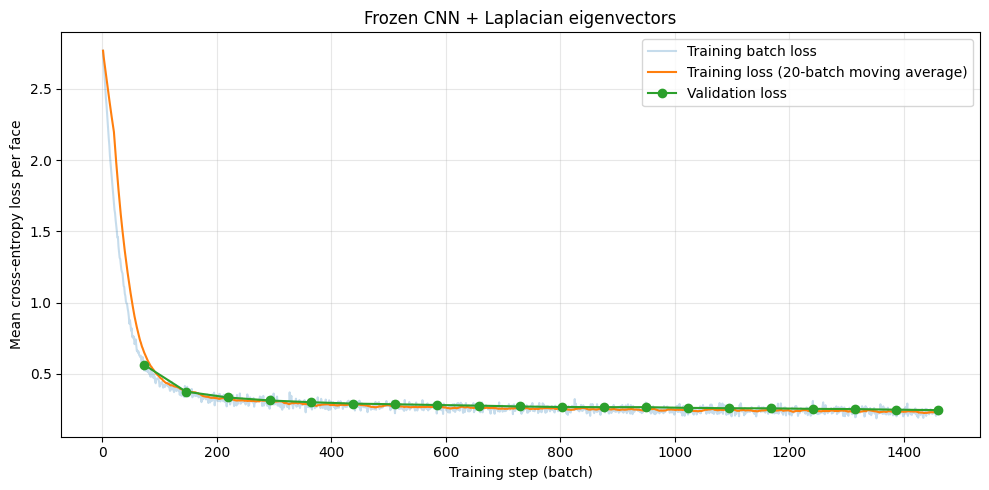

In [35]:
import matplotlib.pyplot as plt
import pandas as pd

batch_log = pd.DataFrame(batch_history)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(batch_log["step"], batch_log["loss"], alpha=0.25, label="Training batch loss")
ax.plot(batch_log["step"], batch_log["loss"].rolling(20, min_periods=1).mean(),
        label="Training loss (20-batch moving average)")
ax.plot([row["step"] for row in history],
        [row["validation_loss"] for row in history], marker="o", label="Validation loss")
ax.set_xlabel("Training step (batch)")
ax.set_ylabel("Mean cross-entropy loss per face")
ax.set_title(f"{training_mode.capitalize()} CNN + Laplacian eigenvectors")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(run_dir / "loss.png", dpi=150)
plt.show()

### 6.2 Accuracy and per-class IoU for the current run

Saved predictions provide loss, accuracy, and intersection over union (IoU)
for all three splits. IoU is `TP / (TP + FP + FN)`, with counts aggregated
across all faces in each split. Mean IoU gives each class equal weight,
includes stock, and excludes classes with zero union.

This cell reads cached predictions without inference. After a kernel restart,
run the imports and configuration cells in section 1, then this cell; encoder
loading and eigenvector preparation are not required. Prediction files for all
three splits must be available at the selected epoch. Set `report_checkpoint_dir`
to inspect another completed run.

In [36]:
# Choose the saved epoch to analyse.
report_checkpoint_dir = run_dir / f"epoch_{num_epochs:03d}"
for split in SPLITS:
    prediction_path = report_checkpoint_dir / f"{split}_predictions.pt"
    if not prediction_path.is_file():
        raise FileNotFoundError(
            f"Missing {prediction_path}. Run final evaluation for all three splits first."
        )

class_names = {}
for label_file in (DATA_DIR / "labels").glob("*.json"):
    with label_file.open() as file:
        faces = json.load(file)["body"]["faces"]
    for face in faces:
        segment = face["segment"]
        class_names[segment["index"]] = segment["name"]
    if len(class_names) == 16:
        break

class_rows = []
summary_rows = []
for split in SPLITS:
    prediction_path = report_checkpoint_dir / f"{split}_predictions.pt"
    results = torch.load(prediction_path, map_location="cpu", weights_only=True)
    labels = results["labels"].long()
    predictions = results["predictions"].long()
    num_classes = results["probabilities"].shape[1]
    confusion = torch.bincount(
        labels * num_classes + predictions, minlength=num_classes**2
    ).reshape(num_classes, num_classes)
    intersection = confusion.diag()
    union = confusion.sum(1) + confusion.sum(0) - intersection
    # Leave out classes with no true or predicted faces when averaging IoU.
    iou = intersection.double() / union.double().masked_fill(union == 0, float("nan"))
    summary_rows.append({
        "split": split,
        "solids": len(results["sample_ids"]),
        "faces": labels.numel(),
        "loss": results["loss"],
        "accuracy": intersection.sum().item() / labels.numel(),
        "mean_iou": iou.nanmean().item(),
    })
    for index in range(num_classes):
        class_rows.append({
            "split": split, "class_index": index,
            "class_name": class_names.get(index, str(index)),
            "support": confusion[index].sum().item(),
            "intersection": intersection[index].item(),
            "union": union[index].item(), "iou": iou[index].item(),
        })

summary = pd.DataFrame(summary_rows).set_index("split")
per_class_iou = pd.DataFrame(class_rows)
display(summary.style.format({"loss": "{:.4f}", "accuracy": "{:.2%}", "mean_iou": "{:.2%}"}))
display(per_class_iou.pivot(index=["class_index", "class_name"],
                           columns="split", values="iou").style.format("{:.2%}"))
summary.to_csv(report_checkpoint_dir / "iou_summary.csv")
per_class_iou.to_csv(report_checkpoint_dir / "per_class_iou.csv", index=False)

,solids,faces,loss,accuracy,mean_iou
split,,,,,
train,9277,209847,0.2286,91.54%,83.46%
validation,3090,70255,0.2445,91.13%,82.53%
test,3094,69411,0.2467,90.89%,82.25%


,split,test,train,validation
class_index,class_name,,,
0,rectangular_through_slot,99.80%,99.97%,99.78%
1,triangular_through_slot,58.98%,61.56%,61.72%
2,rectangular_passage,72.11%,74.38%,71.92%
3,triangular_passage,76.63%,80.09%,80.97%
4,6sides_passage,99.80%,99.90%,99.42%
5,rectangular_through_step,73.03%,74.24%,71.97%
6,2sides_through_step,82.54%,84.55%,82.47%
7,slanted_through_step,99.33%,99.55%,98.76%
8,rectangular_blind_step,98.76%,99.21%,97.85%


### 6.3 Comparison with geometry-only and Laplacian variants

Saved predictions are used to compare the geometry-only model with frozen and
joint Laplacian variants. For each variant, the latest epoch with training and
validation exports is selected. Test scores are included when available at that
same epoch, so earlier runs with only training and validation exports remain visible.

Epoch, loss, accuracy, mean IoU, and per-class metrics are reported without
training or inference. Mean IoU includes stock. This comparison does not select
models by validation or test performance and can run independently after a kernel restart.

In [37]:
# Compare cached final predictions across all completed variants.
import json
import pandas as pd
import torch
from IPython.display import display
from uvnet_project.load_mfcad import DATA_DIR

project_dir = DATA_DIR.parent.parent
variant_dirs = {
    "Geometry only": project_dir / "results/baseline_run_01",
    "Frozen CNN + Laplacian": project_dir / "results/laplacian_run_01",
    "Joint CNN + Laplacian": project_dir / "results/laplacian_joint_run_01",
}
class_names = {}
for label_file in (DATA_DIR / "labels").glob("*.json"):
    with label_file.open() as file:
        faces = json.load(file)["body"]["faces"]
    for face in faces:
        segment = face["segment"]
        class_names[segment["index"]] = segment["name"]
    if len(class_names) == 16:
        break

summary_rows, class_rows = [], []
for variant, directory in variant_dirs.items():
    # Final predictions are written only after training. Use the highest epoch
    # with both splits available, not a partially written final evaluation.
    completed = [folder for folder in directory.glob("epoch_*")
                 if folder.name.removeprefix("epoch_").isdigit()
                 and all((folder / f"{split}_predictions.pt").is_file()
                         for split in ("train", "validation"))]
    if not completed:
        print(f"No completed prediction files yet: {variant}")
        continue
    checkpoint_dir = max(completed, key=lambda folder: int(folder.name.split("_")[-1]))
    epoch = int(checkpoint_dir.name.split("_")[-1])
    available_splits = [split for split in ("train", "validation", "test")
                        if (checkpoint_dir / f"{split}_predictions.pt").is_file()]
    for split in available_splits:
        results = torch.load(checkpoint_dir / f"{split}_predictions.pt",
                             map_location="cpu", weights_only=True)
        labels, predictions = results["labels"].long(), results["predictions"].long()
        num_classes = results["probabilities"].shape[1]
        confusion = torch.bincount(labels * num_classes + predictions,
                                  minlength=num_classes**2).reshape(num_classes, num_classes)
        intersection = confusion.diag()
        support = confusion.sum(1)
        union = support + confusion.sum(0) - intersection
        iou = intersection.double() / union.double().masked_fill(union == 0, float("nan"))
        per_class_accuracy = intersection.double() / support.double().masked_fill(support == 0, float("nan"))
        summary_rows.append(dict(variant=variant, epoch=epoch, split=split,
                                 faces=labels.numel(), loss=results["loss"],
                                 accuracy=intersection.sum().item() / labels.numel(),
                                 mean_iou=iou.nanmean().item()))
        for index in range(num_classes):
            class_rows.append(dict(variant=variant, epoch=epoch, split=split,
                                   class_index=index, class_name=class_names.get(index, str(index)),
                                   support=support[index].item(), iou=iou[index].item(),
                                   accuracy=per_class_accuracy[index].item()))

if summary_rows:
    summary = pd.DataFrame(summary_rows).set_index(["variant", "epoch", "split"])
    per_class_metrics = pd.DataFrame(class_rows)
    display(summary.style.format({"loss": "{:.4f}", "accuracy": "{:.2%}", "mean_iou": "{:.2%}"}))
    print("Per-class IoU (unweighted class mean above, including stock):")
    display(per_class_metrics.pivot(index=["class_index", "class_name"],
                                    columns=["variant", "split"], values="iou").style.format("{:.2%}"))
    summary.to_csv(project_dir / "results/variant_metrics.csv")
    per_class_metrics.to_csv(project_dir / "results/variant_per_class_metrics.csv", index=False)
else:
    print("Run training through final prediction export before comparing metrics.")

Per-class IoU (unweighted class mean above, including stock):


### 6.4 Loss comparison across variants

Epoch-level training and validation losses are read from the saved histories
of the geometry-only model and the two Laplacian variants. Missing runs are
skipped. Test scores are not used to construct training curves. This cell can
run independently after a kernel restart.

Saved comparison: C:\Users\KaiSheng\OneDrive\Desktop\GNN-IN-CAD\results\laplacian_variants_loss.png


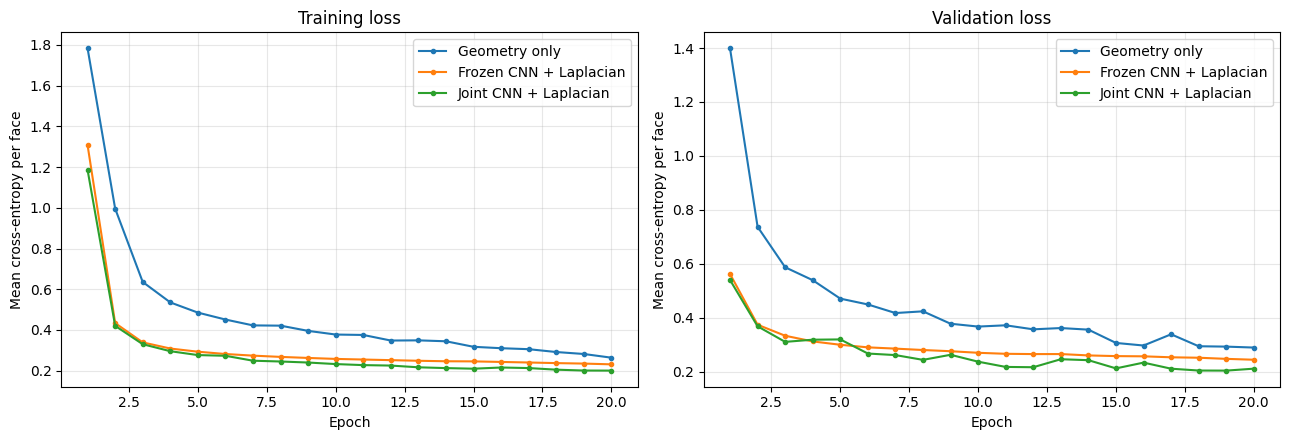

In [38]:
# Comparison from saved histories; no inference or training.
import matplotlib.pyplot as plt
import pandas as pd
from uvnet_project.load_mfcad import DATA_DIR

project_dir = DATA_DIR.parent.parent

variants = {
    "Geometry only": project_dir / "results/baseline_run_01/history.csv",
    "Frozen CNN + Laplacian": project_dir / "results/laplacian_run_01/history.csv",
    "Joint CNN + Laplacian": project_dir / "results/laplacian_joint_run_01/history.csv",
}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plotted = 0
for label, path in variants.items():
    if not path.is_file():
        print(f"Not run yet: {label}")
        continue
    frame = pd.read_csv(path)
    if frame.empty:
        continue
    for ax, metric in zip(axes, ("train_loss", "validation_loss")):
        ax.plot(frame["epoch"], frame[metric], marker="o", markersize=3, label=label)
    plotted += 1
for ax, title in zip(axes, ("Training loss", "Validation loss")):
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Mean cross-entropy per face")
    ax.grid(alpha=0.3)
    if plotted:
        ax.legend()
fig.tight_layout()
if plotted:
    comparison_path = project_dir / "results/laplacian_variants_loss.png"
    fig.savefig(comparison_path, dpi=150)
    print("Saved comparison:", comparison_path)
plt.show()